<a href="https://colab.research.google.com/github/Mahsa-Nobakht/Cahtbot/blob/main/scratchpad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Hello from Google Colab")

Hello from Google Colab


In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("adilshamim8/safety-vests-detection-dataset")

print("Path to dataset files:", path)

100%|██████████| 406M/406M [00:04<00:00, 86.0MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/adilshamim8/safety-vests-detection-dataset/versions/1


In [2]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = ""

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "adilshamim8/safety-vests-detection-dataset",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df.head())

/tmp/ipykernel_3352/3403192222.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


ValueError: Unsupported file extension: ''. Supported file extensions are: .csv, .tsv, .json, .jsonl, .xml, .parquet, .feather, .sqlite, .sqlite3, .db, .db3, .s3db, .dl3, .xls, .xlsx, .xlsm, .xlsb, .odf, .ods, .odt

### 1. Explore the Dataset Directory Structure
Let's list the contents of the downloaded dataset path to see how the images and annotations are organized.

In [3]:
import os

# The dataset path was saved to the variable 'path' in your second cell
dataset_path = path
print("Dataset root directory contents:")
for root, dirs, files in os.walk(dataset_path):
    # Limit depth to keep output readable
    depth = root.replace(dataset_path, '').count(os.sep)
    if depth < 2:
        indent = ' ' * 4 * depth
        print(f"{indent}{os.path.basename(root)}/")
        sub_indent = ' ' * 4 * (depth + 1)
        for f in files[:3]:  # Show up to 3 files per directory
            print(f"{sub_indent}{f}")
        if len(files) > 3:
            print(f"{sub_indent}... and {len(files) - 3} more files")

Dataset root directory contents:
1/
    README.dataset.txt
    train/
    valid/
    test/


### 2. Visualize a Sample Image
Once you find where the images are stored (usually in a folder like `images` or `train`), you can use this code to load and display one of them.

Displaying sample image: /root/.cache/kagglehub/datasets/adilshamim8/safety-vests-detection-dataset/versions/1/train/train/pos_403_jpg.rf.6a89ad20fce427461e10acf1c175e9e9.jpg


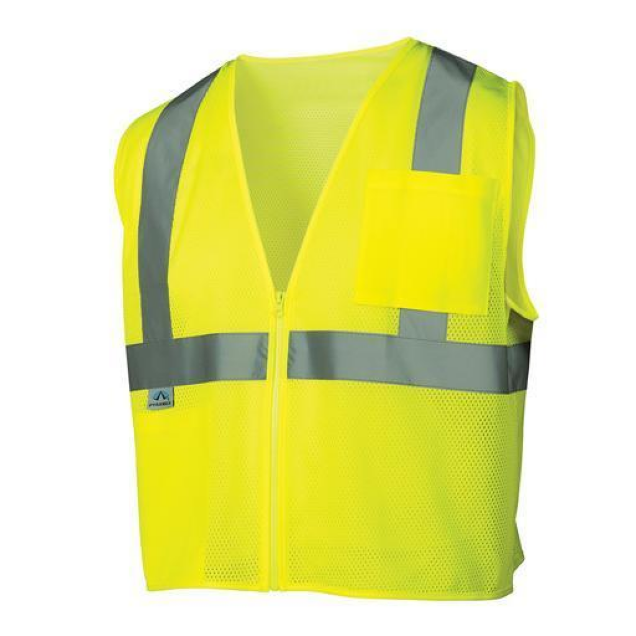

In [6]:
import matplotlib.pyplot as plt
from PIL import Image
import glob

# Find all image files (.jpg or .png) recursively in the dataset
image_extensions = ('/**/*.jpg', '/**/*.png', '/**/*.jpeg')
image_paths = []
for ext in image_extensions:
    image_paths.extend(glob.glob(dataset_path + ext, recursive=True))

if image_paths:
    sample_img_path = image_paths[202]
    print(f"Displaying sample image: {sample_img_path}")
    img = Image.open(sample_img_path)
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.show()
else:
    print("No images found. Please verify the file structure using the directory explorer cell above.")

In [7]:
import glob
import yaml
import os

# Search for configuration files like data.yaml commonly found in object detection datasets
yaml_files = glob.glob(dataset_path + '/**/*.yaml', recursive=True)

if yaml_files:
    print(f"Found configuration file: {yaml_files[0]}\n")
    with open(yaml_files[0], 'r') as f:
        try:
            data_config = yaml.safe_load(f)
            if 'names' in data_config:
                classes = data_config['names']
                print(f"Number of classes: {len(classes)}")
                print(f"Class names: {classes}")
            else:
                print("YAML file found but does not contain a 'names' key. Content:")
                print(data_config)
        except Exception as e:
            print(f"Error reading YAML file: {e}")
else:
    # If no YAML file is found, check README or look for other potential info sources
    readme_files = glob.glob(dataset_path + '/**/README*', recursive=True)
    if readme_files:
        print(f"Found readme file: {readme_files[0]}\n")
        with open(readme_files[0], 'r') as f:
            # Print the first 30 lines to see if classes are documented
            lines = f.readlines()[:30]
            print("".join(lines))
    else:
        print("No configuration (.yaml) or README files found to programmatically determine class names.")

Found readme file: /root/.cache/kagglehub/datasets/adilshamim8/safety-vests-detection-dataset/versions/1/README.dataset.txt

# Safety Vests > 2025-07-06 11:18am
https://universe.roboflow.com/echo-dotf3/safety-vests-c89yh

Provided by a Roboflow user
License: CC BY 4.0


